# Setup

In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery

install.packages("pheatmap")
library(pheatmap)

library(grid)

install.packages("gplots")
library(gplots)

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

system("jupyter nbconvert --to notebook --execute '/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/Setting_Env_Variables.ipynb' --stdout")

[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.2.1     ✔ readr   2.2.0
✔ forcats 1.0.1     ✔ stringr 1.6.0
✔ ggplot2 4.0.2     ✔ tibble  3.3.1
✔ purrr   1.2.1     ✔ tidyr   1.3.2
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Updating HTML index of packages in '.Library'

Making 'packa

# Race, ancestry, SDoH

## Load and merge data

In [2]:
current_directory <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48"
output_dir <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data"


demo_file = paste0(current_directory, "/data/Demographic_and_ancestry_covariates.csv")
demo  <- read_csv(demo_file) |> 
    select(-c(income, education)) |> 
    rename(age = age_at_last_event)

ses_file = paste0(current_directory, "/data/SES_data.csv")
ses_data  <- read_csv(ses_file) 


all_data <- merge(
  demo,
  ses_data,
  by = "person_id"
)

sdoh_var <-c('individual_poverty', 'education',
         'fraction_assisted_income', 'fraction_no_high_school_education', 'lower_median_income', 
         'fraction_no_health_insurance', 'fraction_poverty', 'fraction_vacant_housing', 'deprivation_index'
)


all_data <- all_data %>%
  mutate(across(all_of(sdoh_var), ~ (. - min(., na.rm = TRUE)) / (max(., na.rm = TRUE) - min(., na.rm = TRUE))))


Rows: 135557 Columns: 51
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, education, where_born, military, health...
dbl  (30): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
dttm  (1): basics_survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 214915 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (13): person_id, income, education, per_poverty_threshold, individual_po...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Prepare data for heatmap

In [3]:
cols<-c("Asian", "Black", "Mid", "Multiple", "White", "His", "AIAN", "race_unknown", "PI")
for (col in cols) {
    print(table(all_data[col]))  
}

all_data$AAPI <- ifelse(all_data$PI == 1 | all_data$Asian == 1, 1, 0)


cols<-c("AAPI", "Black", "Mid", "Multiple", "White", "His", "race_unknown", paste0("PC_", 1:8), 
        "individual_poverty", "education", 'fraction_assisted_income',
        'fraction_no_high_school_education', 'lower_median_income', 'fraction_no_health_insurance',
        'fraction_poverty', 'fraction_vacant_housing', 'deprivation_index')


clean_names <- c(
  "Asian & Pacific Islander" = "AAPI",
  "Black" = "Black",
  "Middle Eastern" = "Mid",
  "Multiracial" = "Multiple",
  "White" = "White",
  "Hispanic" = "His",
  "Race Unknown" = "race_unknown",
  "Individual Poverty" = "individual_poverty",
  "Lower Individual Education" = "education",
  "Assisted Income (%)" = "fraction_assisted_income",
  "No High School Education (%)" = "fraction_no_high_school_education",
  "Lower Area Median Income" = "lower_median_income",
  "No Health Insurance (%)" = "fraction_no_health_insurance",
  "Poverty (%)" = "fraction_poverty",
  "Vacant Housing (%)" = "fraction_vacant_housing",
  "Area Deprivation Index" = "deprivation_index"
)

for (i in 1:8) {
  clean_names[paste0("PC_", i)] <- paste0("PC_", i)
}

all_data_clean <- all_data %>% rename(all_of(clean_names))

new_cols<-c("Asian & Pacific Islander", "Black", "Middle Eastern", "Multiracial",
            "White", "Hispanic", "Race Unknown", paste0("PC_", 1:8), 
        "Individual Poverty", "Lower Individual Education", 'Assisted Income (%)',
        'No High School Education (%)', 'Lower Area Median Income', 'No Health Insurance (%)',
        'Poverty (%)', 'Vacant Housing (%)', 'Area Deprivation Index')

Asian
 FALSE   TRUE 
102904   2004 
Black
FALSE  TRUE 
87401 17507 
Mid
 FALSE   TRUE 
104462    446 
Multiple
 FALSE   TRUE 
103267   1641 
White
FALSE  TRUE 
34369 70539 
His
FALSE  TRUE 
92996 11912 
AIAN
 FALSE 
104908 
race_unknown
    0     1 
92185 12723 
PI
 FALSE   TRUE 
104860     48 


## Plot heatmap

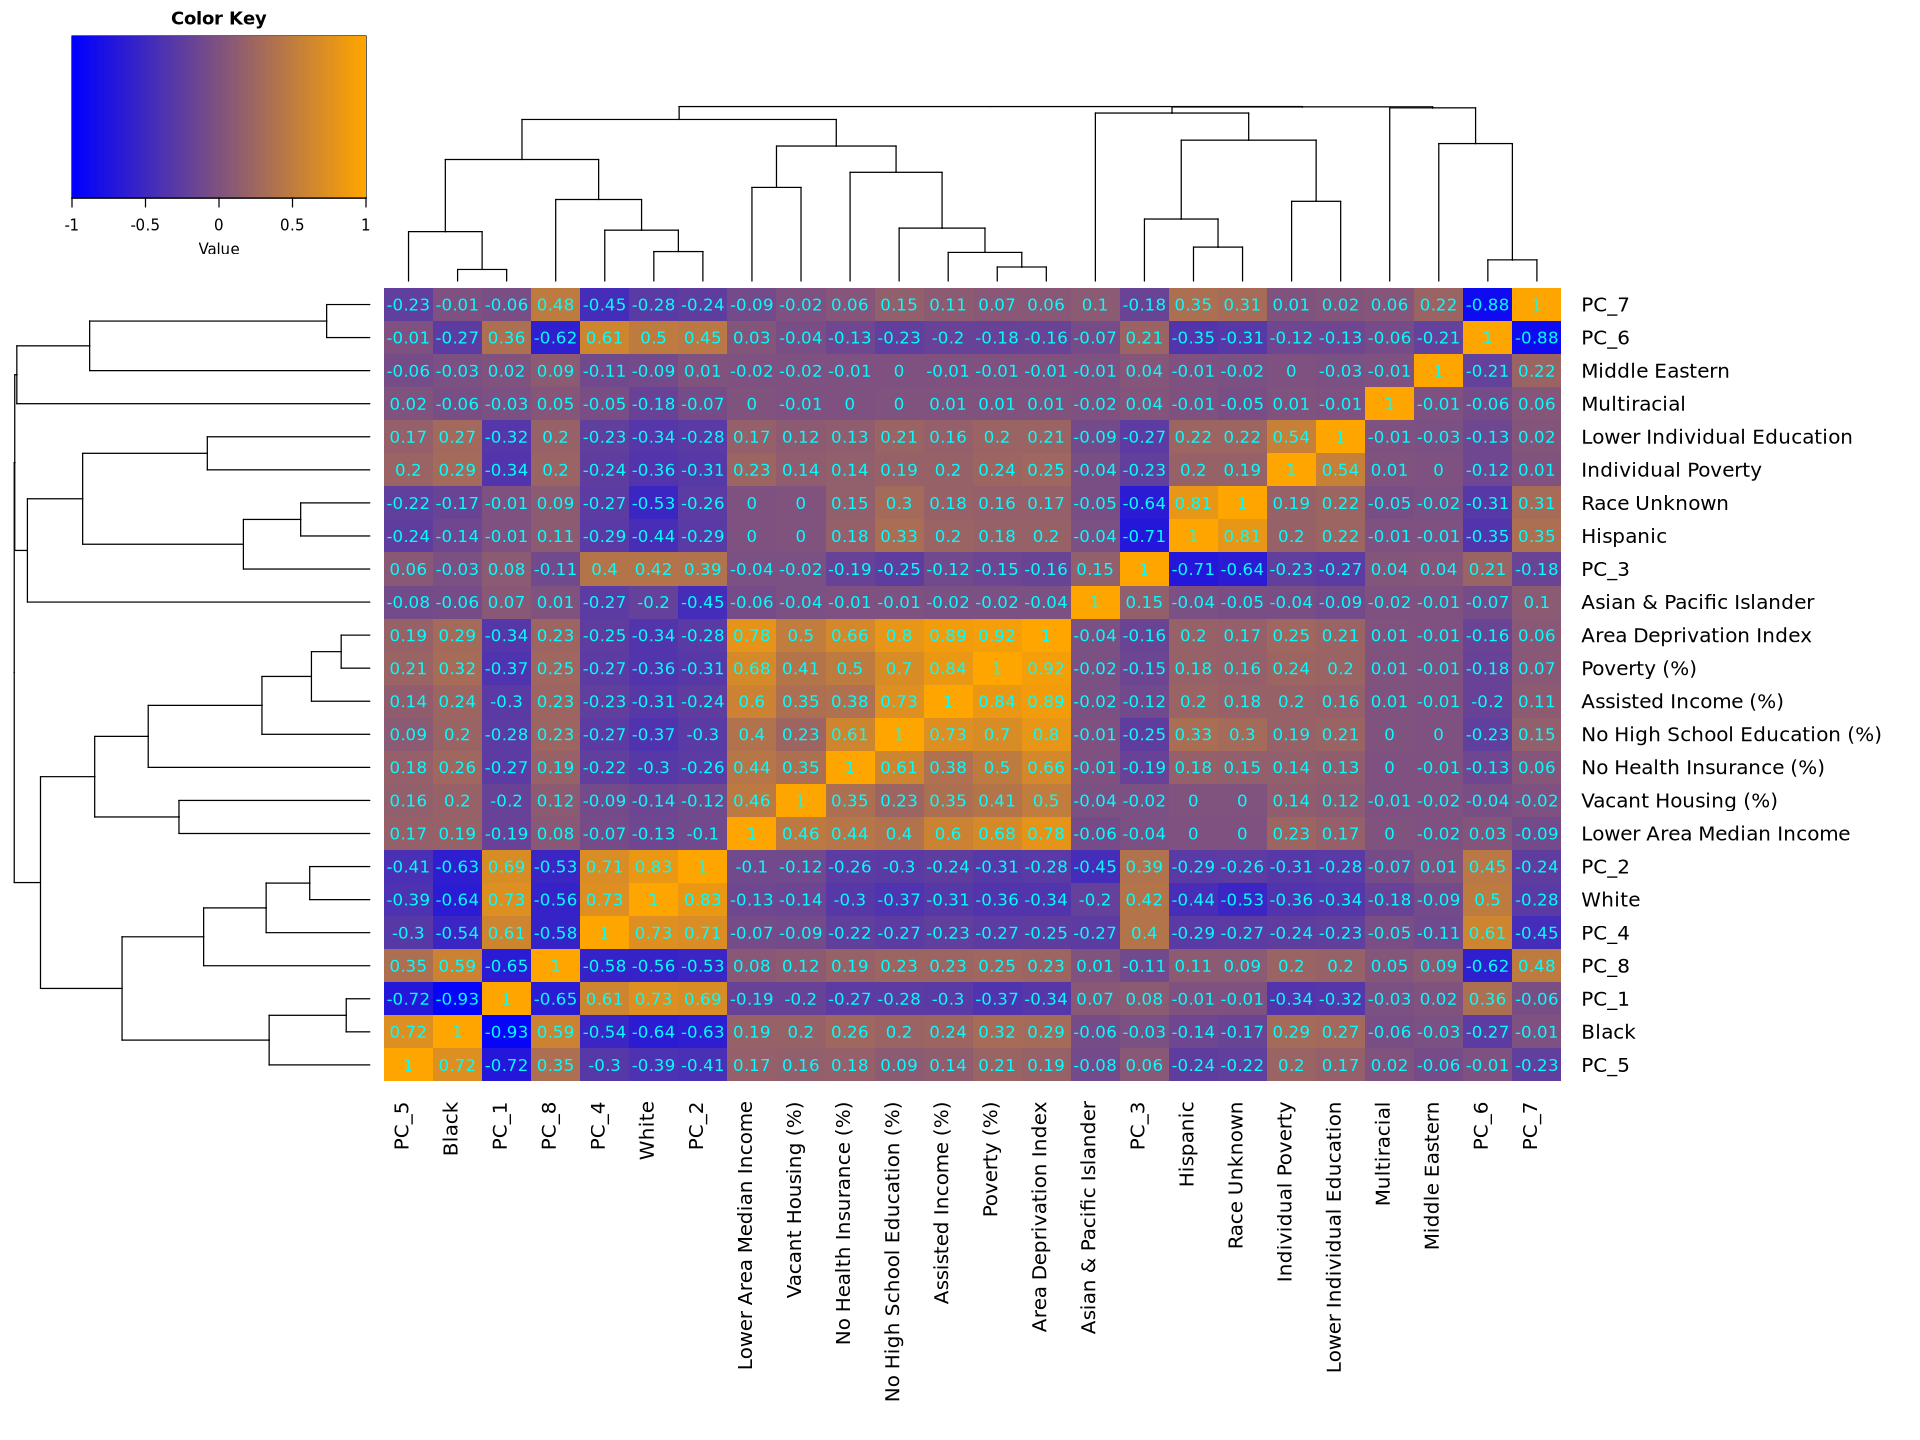

In [4]:
corr <- all_data_clean[, new_cols]

cor_matrix <- cor(corr, use = "pairwise.complete.obs")

# Compute hierarchical clustering
hc <- hclust(as.dist(1 - abs(cor_matrix)), method = "complete")

# Convert to dendrogram object
dend <- as.dendrogram(hc)

# Define custom color palette (orange to blue gradient)
my_palette <- colorRampPalette(c("blue", "orange"))(100)

# Assuming your correlation matrix is stored in 'correlation_matrix'

options(repr.plot.width = 16, repr.plot.height = 12)  # Set width and height

cell_labels <- round(cor_matrix, 2)


# Create the heatmap
heatmap.2(cor_matrix, 
          Rowv = dend,  # Use the dendrogram for row clustering
          Colv = dend,  # Use the same dendrogram for column clustering
          cexRow = 1.2,
          cexCol = 1.2,
          dendrogram = "both",  # Show dendrogram for both rows and columns
          scale = "none",  # Do not scale data
          key = TRUE,  # Show color key
          keysize = 1.0,  # Size of color key
          trace = "none",  # Do not show trace lines
          density.info = "none",  # Do not show density plot
          cellnote = cell_labels,  # Add correlation values as labels
          margins = c(18, 18),  # Set margins
          main = "",  # Main title
          col = my_palette  # Use custom color 
)

# Adjusted PRS and SDoH

## Load and merge data

In [5]:
#Load PRS data

PRS_file <-  paste0(current_directory, "/data/adjusted_PRS_scores.csv") 
PRS  <- read_csv(PRS_file) 

#MERGE
all_data2<-merge(all_data, PRS, on="person_id", how="inner")


prs_vars<-names(all_data2)[grepl("_adjusted_score", names(all_data2))]


social_name_mapping <- c(
"individual_poverty" = "Individual Poverty",
  "education" = "Lower Individual Education", 
  "fraction_assisted_income" = "Assisted Income (%)",
  "fraction_no_high_school_education" = "No High School Education (%)",
  "lower_median_income" = "Lower Area Median Income",
  "fraction_no_health_insurance" = "No Health Insurance (%)",
  "fraction_poverty" = "Poverty (%)",
  "fraction_vacant_housing" = "Vacant Housing (%)",
  "deprivation_index" = "Area Deprivation Index"
)

disease_name_mapping <-c(
    "Asthma_adjusted_score" = "Asthma", 
    "Afib_adjusted_score" = "Afib",
    "BreastC_adjusted_score" = "Breast Cancer",
    "CKD_adjusted_score" = "CKD",
    "CHD_adjusted_score" = "CHD",
    "ProstateC_adjusted_score" = "Prostate Cancer",
    "t2d_adjusted_score" = "T2D",
    "t1d_adjusted_score" = "T1D"

)

Rows: 135557 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (9): person_id, Asthma_adjusted_score, Afib_adjusted_score, BreastC_adju...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Make and plot heatmap

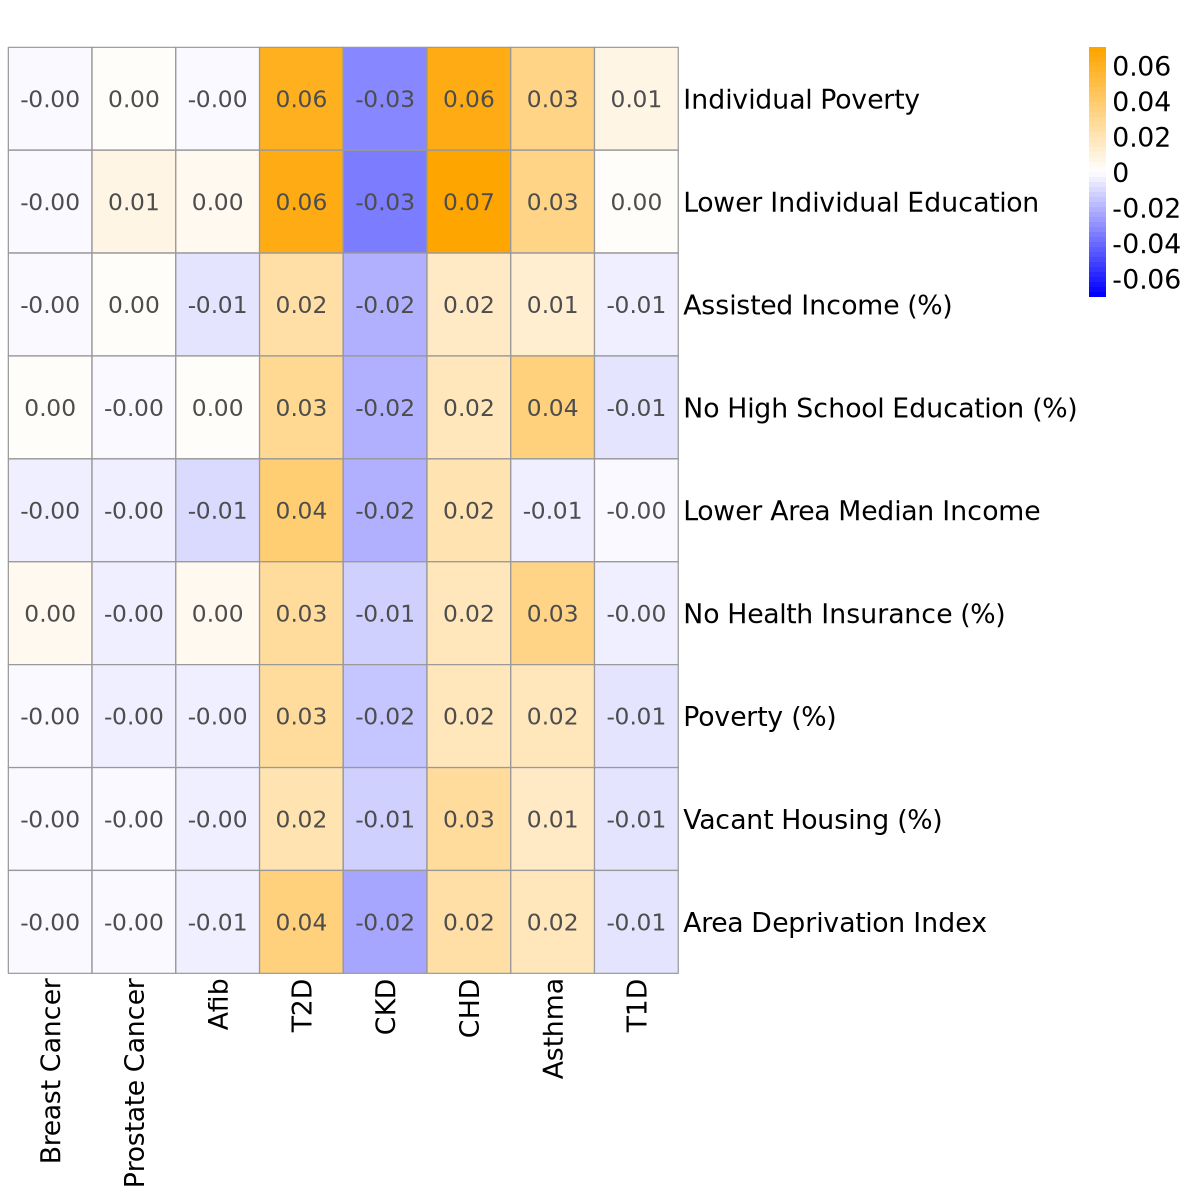

In [6]:
options(repr.plot.width = 10, repr.plot.height = 10)  # Set width and height

cor_data <- all_data2 %>%
  select(all_of(c(sdoh_var,prs_vars))) %>%
  mutate(across(everything(), ~ as.numeric(as.character(.))))

cor_mat <- cor(
  cor_data[, sdoh_var],
  cor_data[,prs_vars],
  use = "pairwise.complete.obs",
  method = "pearson"
)

# Create diverging color scale centered at 0
max_abs <- max(abs(cor_mat), na.rm = TRUE)

breaks <- seq(-max_abs, max_abs, length.out = 51)
colors <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)

#Make prettier
rownames(cor_mat) <- social_name_mapping[rownames(cor_mat)]
colnames(cor_mat) <- disease_name_mapping[colnames(cor_mat)]

prs_order <-c("Breast Cancer", "Prostate Cancer", "Afib", "T2D",
          "CKD", "CHD", "Asthma", "T1D")

cor_mat_adj <- cor_mat[,prs_order, drop = FALSE]


B_plot<- pheatmap(
  cor_mat_adj,
  color = colors,
  breaks = breaks,
  cluster_rows = FALSE,
  cluster_cols = FALSE,
  display_numbers = TRUE,
  number_format = "%.2f",
  fontsize_number = 14,
  fontsize_row = 16,
  fontsize_col = 16,
  fontsize = 16,
  angle_col = 90,
  main = " "
)


# Un-Aajusted PRS and SDoH

In [7]:
# Define conditions and readable disease names
conditions <- c(
  "asthma",
  "atrial_fibrilation",
  "breast_cancer",
  "ckd",
  "coronary_heart_disease",
  "hypercholesterolemia",
  "prostate_cancer",
  "t1d",
  "t2d"
)

disease_labels <- c(
  "Asthma",
  "Afib",
  "BreastC",
  "CKD",
  "CHD",
  "HyperC",
  "ProstateC",
  "t1d",
  "t2d"
)


all_prs <- NULL


# Loop through all conditions
for (i in seq_along(conditions)) {
  condition <- conditions[i]
  disease <- disease_labels[i]
  
  # Define filename
  name_of_file_in_bucket <- paste0(current_directory, "/data/combined_", condition, ".txt")
  
  # Read CSV
  prs <- read_csv(name_of_file_in_bucket, show_col_types = FALSE) |> select(1,4)
  
  # Add disease label and rename the score column
  prs <- prs %>%
  rename(!!paste0(disease, "_score") := 2) %>%
  rename("person_id" := 1)
  
  # Merge by IID
  if (is.null(all_prs)) {
    all_prs <- prs
  } else {
    all_prs <- merge(all_prs, prs, by = "person_id")
  }
}


#MERGE
merged_data<-merge(all_data, all_prs, on="person_id", how="inner")

prs_vars<-names(merged_data)[grepl("_score", names(merged_data))]

merged_data <- merged_data %>%
  mutate(
    across(
      ends_with("_score"),
      ~ (. - mean(., na.rm = TRUE)) / sd(., na.rm = TRUE)
    )
  )

In [8]:
disease_name_mapping <-c(
    "Asthma_score" = "Asthma", 
    "Afib_score" = "Afib",
    "BreastC_score" = "Breast Cancer",
    "CKD_score" = "CKD",
    "CHD_score" = "CHD",
    "ProstateC_score" = "Prostate Cancer",
    "t2d_score" = "T2D",
    "t1d_score" = "T1D"

)

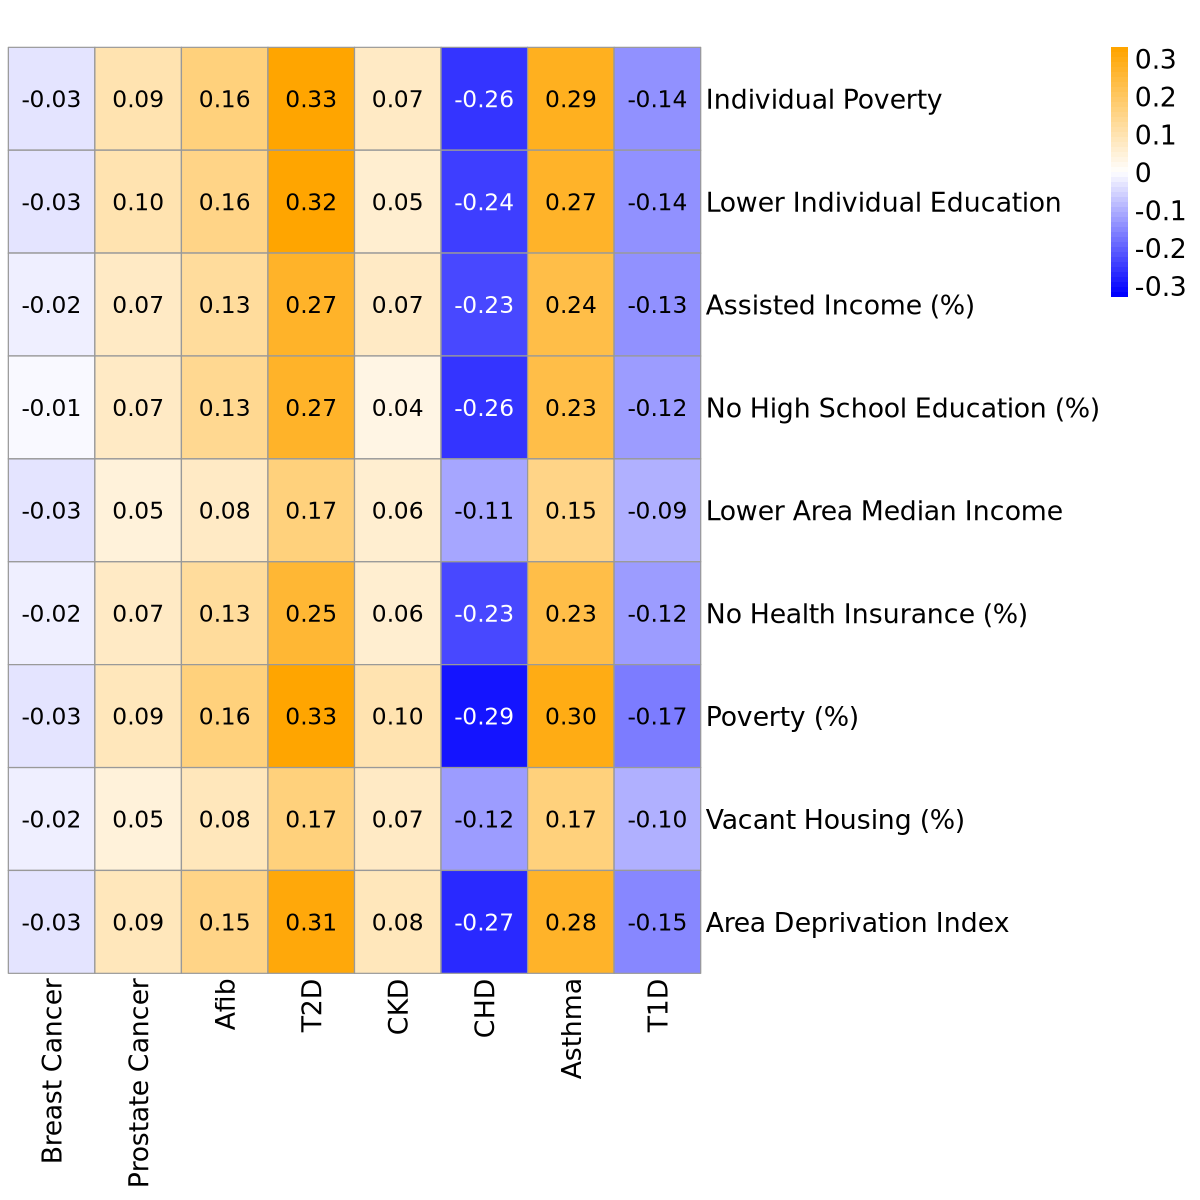

In [9]:
options(repr.plot.width = 10, repr.plot.height = 10)  # Set width and height

cor_data <- merged_data %>%
  select(all_of(c(sdoh_var,prs_vars))) %>%
  mutate(across(everything(), ~ as.numeric(as.character(.))))

cor_mat <- cor(
  cor_data[, sdoh_var],
  cor_data[,prs_vars],
  use = "pairwise.complete.obs",
  method = "pearson"
)

# Create diverging color scale centered at 0
max_abs <- max(abs(cor_mat), na.rm = TRUE)

breaks <- seq(-max_abs, max_abs, length.out = 51)
colors <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)


rownames(cor_mat) <- social_name_mapping[rownames(cor_mat)]
colnames(cor_mat) <- disease_name_mapping[colnames(cor_mat)]

prs_order <-c("Breast Cancer", "Prostate Cancer", "Afib", "T2D",
          "CKD", "CHD", "Asthma", "T1D")

cor_mat_unadj <- cor_mat[,prs_order, drop = FALSE]

text_col_mat <- matrix(
  ifelse(cor_mat_unadj < -0.2, "white", "black"),
  nrow = nrow(cor_mat_unadj),
  ncol = ncol(cor_mat_unadj),
  dimnames = dimnames(cor_mat_unadj)
)


final_A_plot<- pheatmap(
  cor_mat_unadj,
  color = colors,
  breaks = breaks,
  cluster_rows = FALSE,
  cluster_cols = FALSE,
  display_numbers = TRUE,
  number_color = text_col_mat, 
  number_format = "%.2f",
  fontsize_number = 14,
  fontsize_row = 16,
  fontsize_col = 16,
  fontsize = 16,
  angle_col = 90,
  main = " "
)

## B plot with same color scale as A

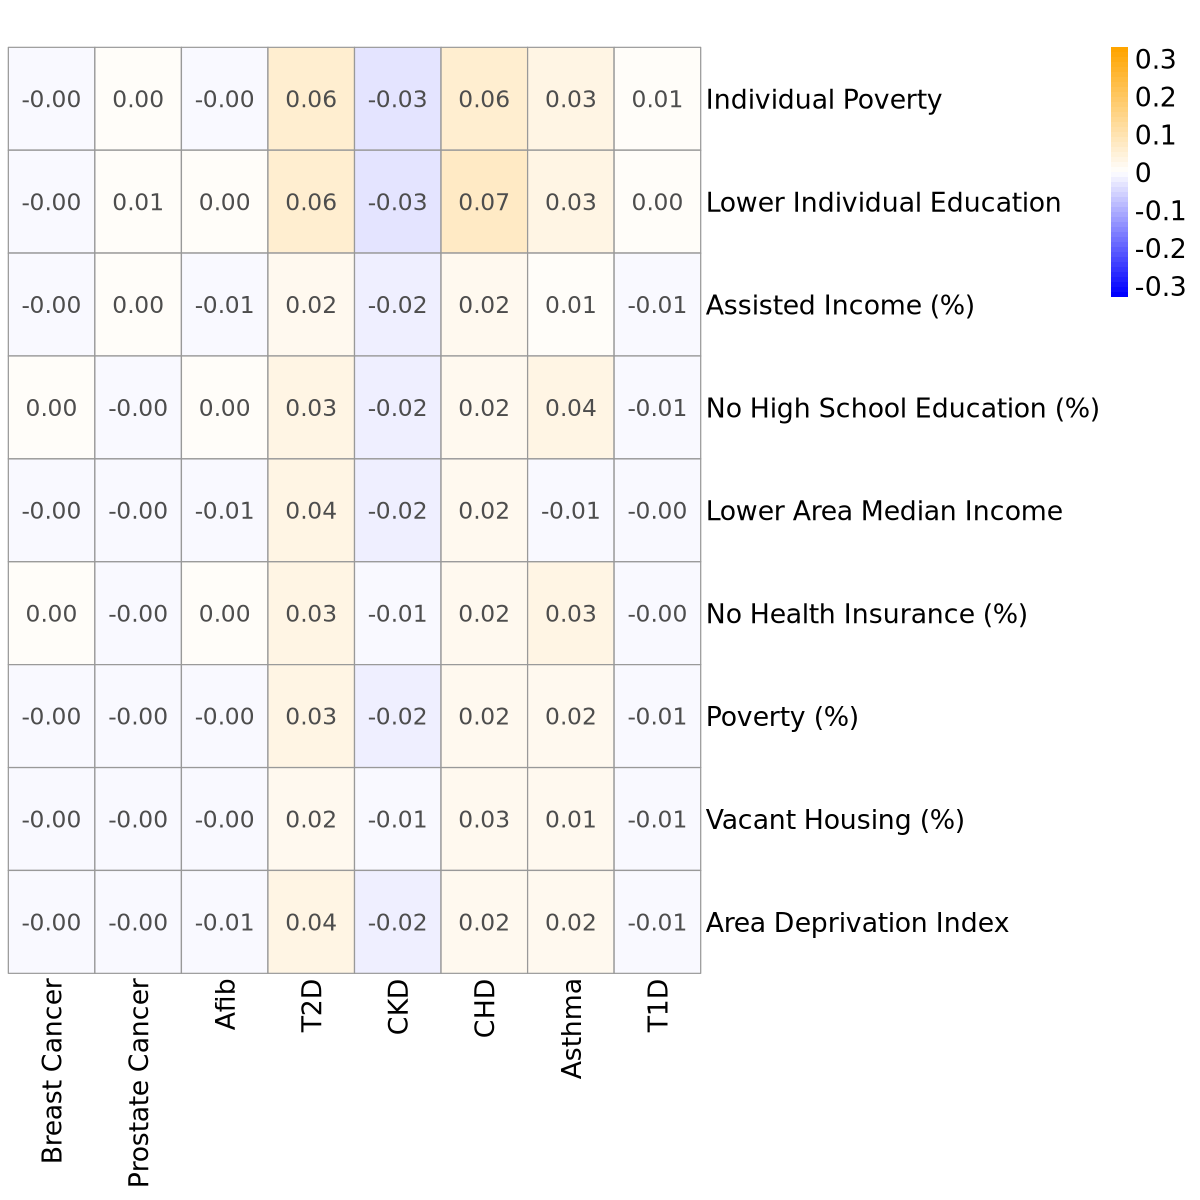

In [10]:
final_B_plot<- pheatmap(
  cor_mat_adj,
  color = colors,
  breaks = breaks,
  cluster_rows = FALSE,
  cluster_cols = FALSE,
  display_numbers = TRUE,
  number_format = "%.2f",
  fontsize_number = 14,
  fontsize_row = 16,
  fontsize_col = 16,
  fontsize = 16,
  angle_col = 90,
  main = " "
)

# Plot together


Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




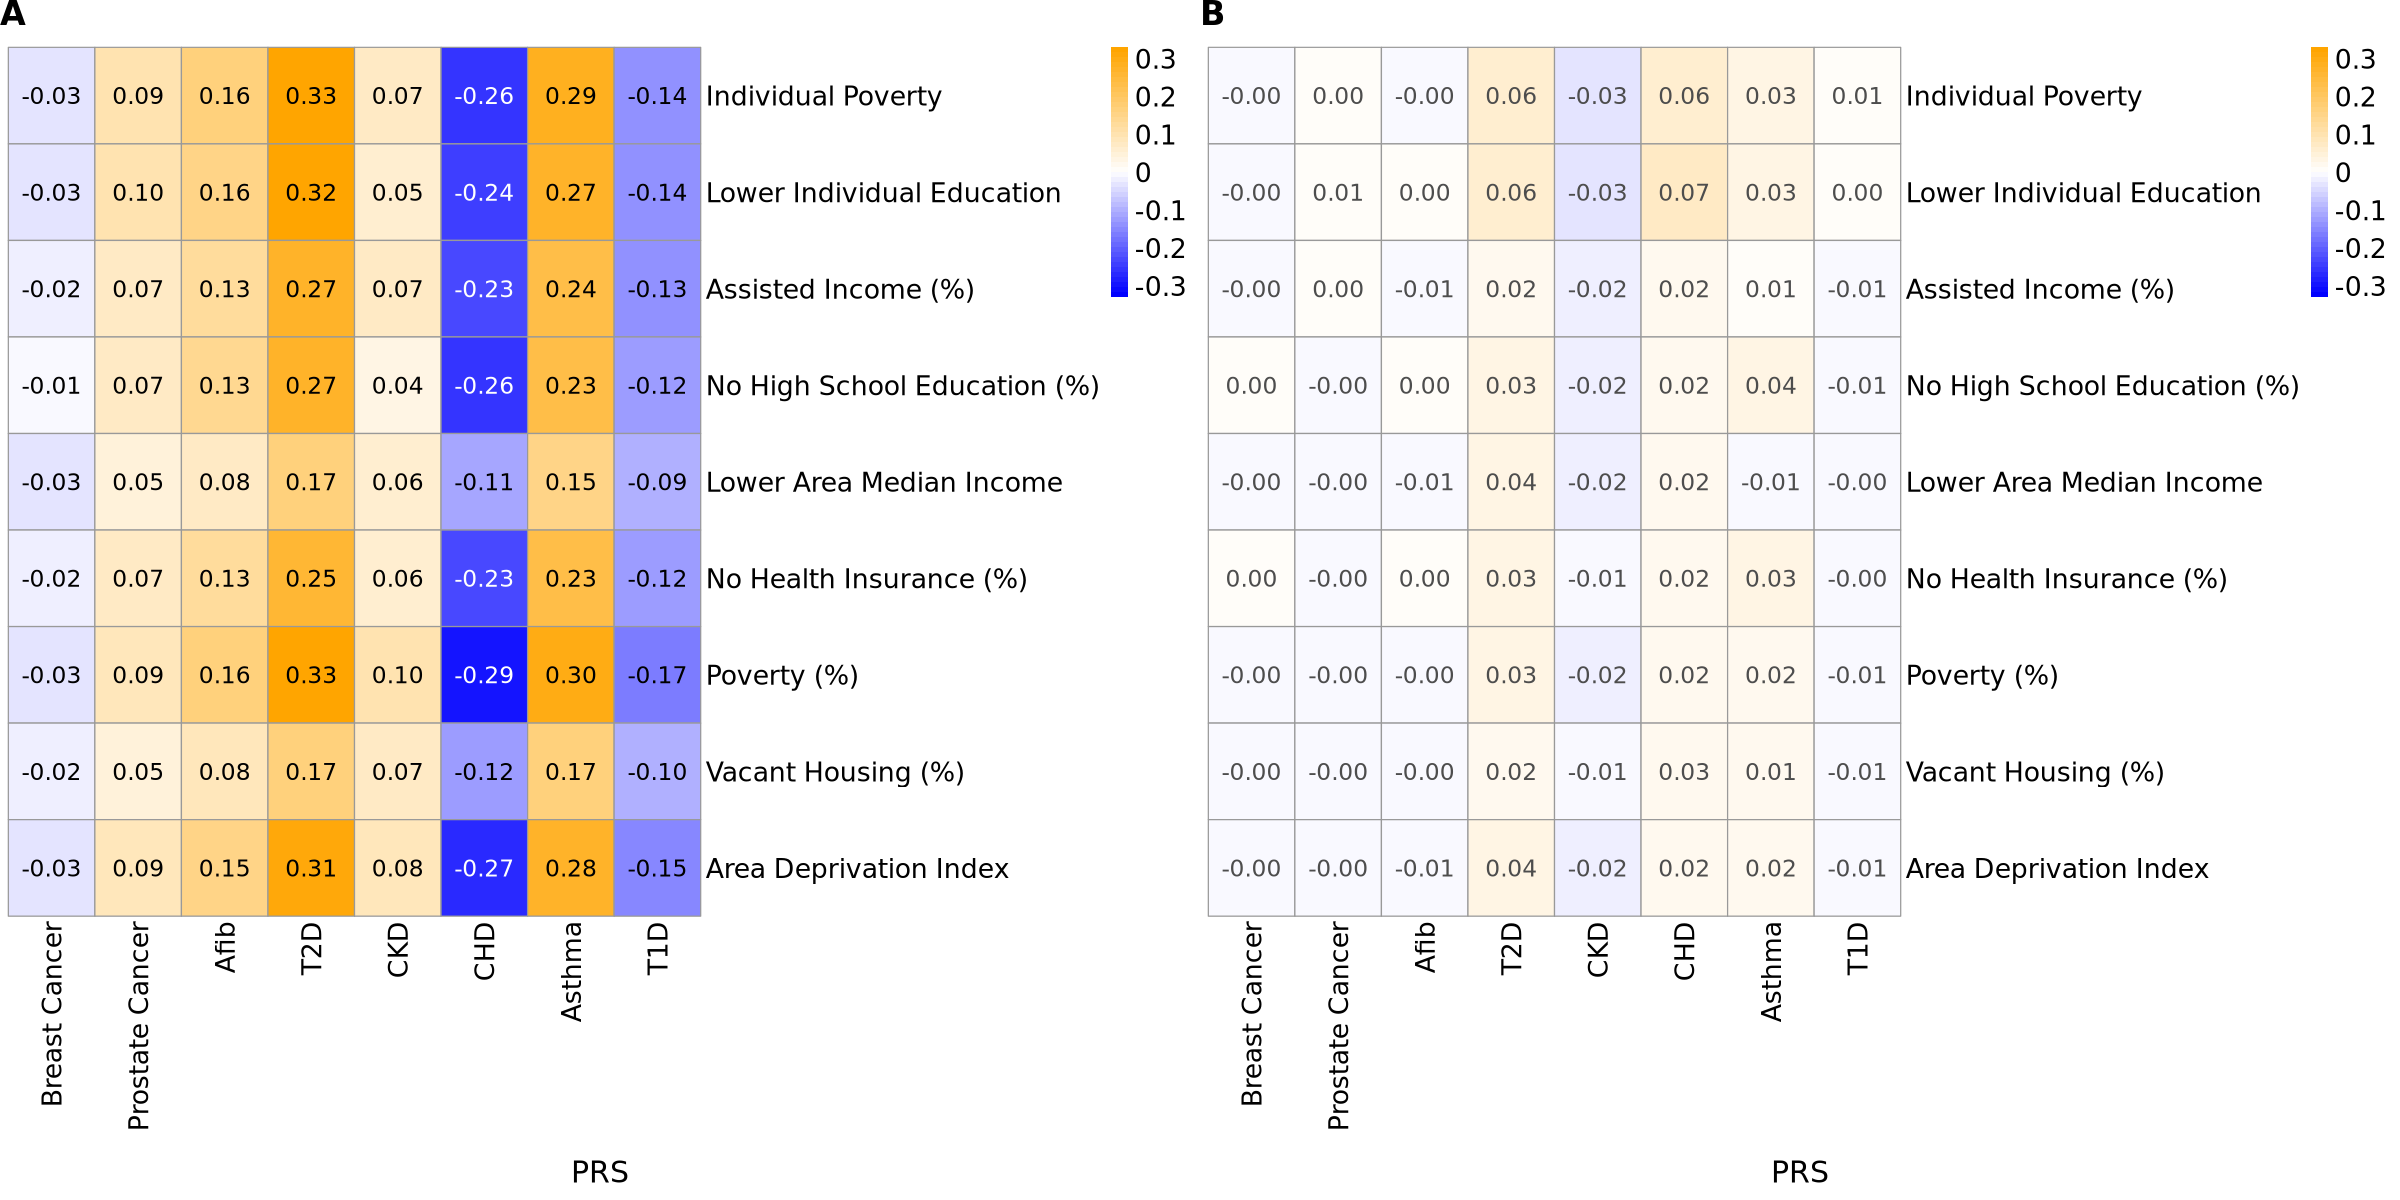

In [11]:
#AB Plot 
options(repr.plot.width = 20, repr.plot.height = 10)  # Set width and height


library(grid)
library(gridExtra)

gA <- final_A_plot$gtable
gB <- final_B_plot$gtable


label_A <- textGrob("A", x = unit(0, "npc"), y = unit(1, "npc"),
                    just = c("left", "top"),
                    gp = gpar(fontsize = 20, fontface = "bold"))

label_B <- textGrob("B", x = unit(0, "npc"), y = unit(1, "npc"),
                    just = c("left", "top"),
                    gp = gpar(fontsize = 20, fontface = "bold"))

prs_label <- textGrob("PRS", gp = gpar(fontsize = 18))


panel_A <- arrangeGrob(
  label_A,
  gA,
  prs_label,
  heights = c(0.0, 1, 0.05)
)

panel_B <- arrangeGrob(
  label_B,
  gB,
  prs_label,
  heights = c(0.0, 1, 0.05)
)

grid.arrange(panel_A, panel_B, ncol = 2)



